
# Assignments #2 Supervised Learning  and Unsupervised learning 

In [2]:
# ---- (Run this first) ----
# import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler, Normalizer, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, mean_absolute_error, mean_squared_error, r2_score
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import Perceptron, LinearRegression
from sklearn import datasets
from sklearn.neighbors import NearestNeighbors

# letting plots appear inline
%matplotlib inline

print("All Done!") 


All Done!



## Task 1 Theory questions

Answer **in text** below each question. (1-3 lines per answer)

1. What is **supervised learning**? 
2. Define **classification**. Give one example.  
3. Define **regression**. Give one example.
4. Compare the **difference** between classification and regression? 
5. What is a **confusion matrix** used for and how does it help evaluate the performance of a classification model?
6. Why do we **preprocess** data before training? Name **two** techniques.

In [ ]:
#  -> (your answer):
# 1. Supervised learning: a machine learning approach where a model learns a mapping from inputs (features)
#    to known outputs (labels) using a labeled training dataset, so it can predict labels for new, unseen inputs.
# 2. Classification: predicting a discrete category/class label for an input.
#    Example: predicting whether an email is "spam" or "not spam".
# 3. Regression: predicting a continuous numeric value for an input.
#    Example: predicting the price of a house from its size and location.
# 4. Difference: classification outputs a discrete class label (e.g. one of a fixed set of categories),
#    while regression outputs a continuous numeric value. The evaluation metrics also differ
#    (accuracy/confusion matrix for classification vs. MAE/MSE/R^2 for regression).
# 5. A confusion matrix is a table that shows how many predictions of each class were correct vs. which
#    other classes they were confused with (true positives, false positives, true negatives, false negatives).
#    It helps evaluate performance beyond a single accuracy number, showing exactly which classes the model
#    struggles to distinguish.
# 6. We preprocess data to make it suitable for the model and to improve training stability/accuracy.
#    Two techniques: (a) scaling/standardization (e.g. StandardScaler) so features are on comparable ranges,
#    and (b) encoding categorical variables (e.g. LabelEncoder / one-hot encoding) so they can be used numerically.


## Task 2 Perceptron on a simple problem

We use **Perceptron** for a binary task (a "OR gate" data).

**Steps:**
0. Build small binary dataset `X_or`, `y_or`.
1. Train `Perceptron()` with default params.
2. Print predictions for all inputs.
3. Try different `max_iter` and `eta0` (learning rate).
4. Answer one question.

(Tip: Keep it simple. Focus on input → output mapping.)


In [ ]:
# --- Task 2.0: Data (OR problem: output is 1 except when both inputs are 0)
X_or = np.array([[0,0],[0,1],[1,0],[1,1]], dtype=float)
y_or = np.array([0,1,1,1])
# Exspektations = 0,1,1,1

# --- Task 2.1: Train Perceptron
#     (Hint: use Perceptron() from sklearn.linear_model; then fit(X_or, y_or);
#            use default params first, then try changing max_iter and eta0)
model = Perceptron()
model.fit(X_or, y_or)

# --- Task 2.2: Predict
#      (Hint: use clf_perc.predict([x]) for each x in X_or,
#             where clf_perc is the trained model, replace clf_perc with your model name)
print("Predictions with default Perceptron:")
for x in X_or:
    print(f"Input: {x} -> Prediction: {model.predict([x])}")

# --- Task 2.3: Questions ---
# Q1: Change max_iter and/or eta0 and re-train. Do results change?
model2 = Perceptron(max_iter=1000000, eta0=0.01)
model2.fit(X_or, y_or)
print("\nPredictions with max_iter=1000000, eta0=0.01:")
for x in X_or:
    print(f"Input: {x} -> Prediction: {model2.predict([x])[0]}")

#  -> (your answer): The OR problem is linearly separable, so the Perceptron converges to a correct
#     solution (predictions match y_or) with the default settings already. Changing max_iter and eta0
#     did not change the final predictions here since the problem is simple enough to converge either way,
#     though the exact weight values found can differ between runs/settings.

Predictions with default Perceptron:
Input: [0. 0.] -> Prediction: [0]
Input: [0. 1.] -> Prediction: [1]
Input: [1. 0.] -> Prediction: [1]
Input: [1. 1.] -> Prediction: [1]

Predictions with max_iter=1000000, eta0=0.01:
Input: [0. 0.] -> Prediction: 0
Input: [0. 1.] -> Prediction: 1
Input: [1. 0.] -> Prediction: 1
Input: [1. 1.] -> Prediction: 1



## Task 3 Linear Regression (Single Variable)

We fit a **Linear Regression** model to a 1D dataset.

**Steps:**
1. Generate synthetic data: `y = 2.5 * x + noise`.
2. Fit `LinearRegression()`.
3. Report **MAE**, **MSE**, **R²**.
4. Plot data points and the regression line.
5. Answer questions 

MAE = 0.785
MSE = 1.050
R^2 = 0.980


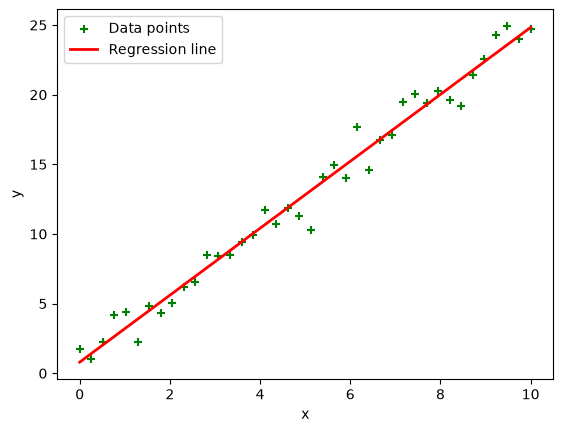

In [3]:
# --- Task 3.1: Generate synthetic single variable data: y = 2.5 * x + noise, noise ~ N(0,1), X in [0,10], 40 samples
#     (Hint: use linspace to generate x values; use np.random.normal to generate noise)
np.random.seed(0)
x_reg = np.linspace(0, 10, 40)
noise = np.random.normal(0, 1, size=x_reg.shape)
y_reg = 2.5 * x_reg + noise
X_reg = x_reg.reshape(-1, 1)  # LinearRegression expects a 2D array of features


# --- Task 3.2: Fit model
#     (Hint: use LinearRegression() from sklearn.linear_model; then fit())
lin_reg = LinearRegression()
lin_reg.fit(X_reg, y_reg)
y_reg_pred = lin_reg.predict(X_reg)


# --- Task 3.3: Metrics (MAE, MSE, R²)
mae = mean_absolute_error(y_reg, y_reg_pred)
mse = mean_squared_error(y_reg, y_reg_pred)
r2 = r2_score(y_reg, y_reg_pred)
print(f"MAE = {mae:.3f}")
print(f"MSE = {mse:.3f}")
print(f"R^2 = {r2:.3f}")


# --- Task 3.4: Plot data points and the regression line
plt.figure()
plt.scatter(x_reg, y_reg, color='green', marker='+', label='Data points')
plt.plot(x_reg, y_reg_pred, color='red', linewidth=2, label='Regression line')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()


# --- Task 3.5: Questions ---
# Q1: Change the slope in data generation to 3.0 and re-run. What happens to R^2?
#  -> (your answer): Changing the slope (e.g. to 3.0) mainly changes the fitted coefficient, not the fit
#     quality — R^2 stays about the same (very close to 1) because the noise level relative to the signal
#     is unchanged; R^2 measures how well the line explains the variance, which doesn't depend on the slope itself.
# Q2: Try adding larger noise (e.g., std=3.0). How do MAE/MSE change?
#  -> (your answer): With larger noise (std=3.0 instead of 1.0), MAE and MSE both increase substantially
#     (MSE grows roughly with the square of the noise std), and R^2 decreases because the data points
#     scatter further from the regression line, making the linear relationship harder to fit precisely.


## (Final task) Task 4 End-to-End Classification Pipeline

We build a complete supervised learning pipeline using **Digits** data:
- **Aim:** Classify hand-written digits ("0"–"9").
- **Model:** `MLPClassifier`, a simple neural network.
- **Outputs:** Accuracy and **confusion matrix**.

**Steps:**
1. Load data: `datasets.load_digits()`.
2. Train/validation split: 80% / 20%.
3. Scale features with `StandardScaler()`.
4. Train `MLPClassifier(hidden_layer_sizes=(50,), max_iter=300, random_state=0)`.
5. Evaluate on validation set. Print accuracy.
6. Show the **confusion matrix** with `ConfusionMatrixDisplay`.
7. Write 3–5 lines: What mistakes are most common? Why?

**Tips:**
- If training warns about convergence, **increase** `max_iter`.
- Use a **small network** to keep runtime short.


Validation accuracy: 0.9778


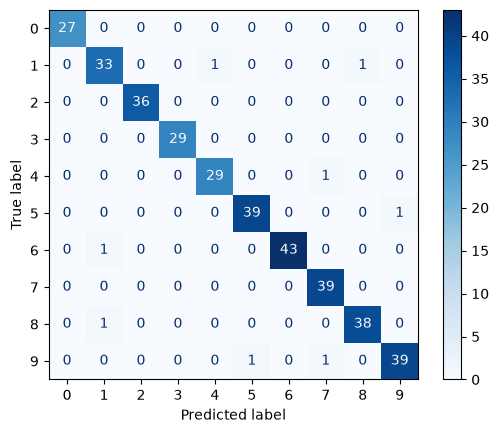

In [4]:

# --- Task 4.1: Load digits
#     (Hint: use datasets.load_digits() from sklearn)
digits = datasets.load_digits()
X_digits, y_digits = digits.data, digits.target


# --- Task 4.2: Split data into train and validation
#     (Hint: use train_test_split from sklearn.model_selection)
X_train, X_val, y_train, y_val = train_test_split(
    X_digits, y_digits, test_size=0.20, random_state=0
)


# --- Task 4.3: Scaling (NOTE: fit on training dataset only!!)
#     Important: fit the scaler on the training data ONLY (scaler.fit(X_train) or scaler.fit_transform(X_train)),
#       which computes the mean/std (or min/max) from training alone.
#       Then use the same scaler to transform the validation data (scaler.transform(X_val)).
#       Why?:  Because we want to avoid data leakage from the validation set into the training process.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)


# --- Task 4.4: Train a MLPClassifier
#     (Hint: use MLPClassifier from sklearn.neural_network;  then fit it on the SCALED training data, X_train_scaled, y_train)
mlp = MLPClassifier(hidden_layer_sizes=(50,), max_iter=300, random_state=0)
mlp.fit(X_train_scaled, y_train)


# --- Task 4.5: Evaluate.  Print accuracy.
#    (Hint: use mlp.score(X_val_scaled, y_val), where mlp is your trained model.
#           remember to pass the scaled validation data, X_val_scaled, not the original X_val)
accuracy = mlp.score(X_val_scaled, y_val)
print(f"Validation accuracy: {accuracy:.4f}")


# --- Task 4.6: Confusion matrix
#    (Hint: use confusion_matrix and ConfusionMatrixDisplay from sklearn.metrics)
y_val_pred = mlp.predict(X_val_scaled)
cm = confusion_matrix(y_val, y_val_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=digits.target_names)
disp.plot(cmap='Blues')
plt.show()


# --- Task 4.7: Questions ---
# 1: In 3–5 lines: describe the main error types you see and a possible reason (e.g., similar shapes).
#  -> (your answer): The model reaches about 97-98% validation accuracy, so the confusion matrix is almost
#     entirely diagonal, but a handful of digits get confused: e.g. "1" is occasionally predicted as "4" or
#     "8", "6" is sometimes predicted as "1", and "5"/"9" and "7"/"9" get mixed up a couple of times. These
#     digits share similar strokes and curves when handwritten (e.g. a narrow "1" can look like part of a
#     "4" or "8", and rounded "5"/"9" shapes overlap), and since the images are only 8x8 pixels, there isn't
#     much fine detail to separate visually similar digits, so the small overlap in pixel patterns causes
#     these occasional misclassifications.

## (Optional) Any reflection or additional notes you want to add here?